In [1]:
import pandas as pd

import json

D = pd.read_csv("data_flat/D.csv").set_index("zone_id")

T = pd.read_csv("data_flat/T.csv", index_col=0)
P = pd.read_csv("data_flat/P.csv", index_col=0)

In [2]:
training_ds = pd.read_csv('data_flat/training_dataset.csv')

In [3]:
zone_sequences_reduced = pd.read_csv('data_flat/zone_sequences_reduced_ML.csv')

In [4]:
zone_sequences_reduced.head()

,route_id,zone_id,min_lat,max_lat,min_lng,max_lng,center_lat,center_lon,station_code,zone_sequence_reduced
0,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,A-2.2A,34.088467,34.088717,-118.286484,-118.284521,34.088631,-118.285281,DLA3,1
1,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,A-2.1A,34.089727,34.090901,-118.285530,-118.284257,34.090314,-118.284893,DLA3,2
2,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,A-1.1A,34.091721,34.092285,-118.284539,-118.283236,34.092003,-118.283888,DLA3,3
3,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,A-1.2A,34.092890,34.094506,-118.284798,-118.282396,34.093508,-118.283406,DLA3,4
4,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,A-1.3A,34.091500,34.095431,-118.286891,-118.285547,34.093342,-118.286300,DLA3,5


In [5]:
import pandas as pd
import numpy as np
from itertools import product

In [6]:
def parse_zone(zone):

    try:
        part1, rest = zone.split("-")

        z2 = int(rest.split(".")[0])

        tmp = rest.split(".")[1]

        z3 = int(tmp[:-1])

        z4 = tmp[-1]

        return part1, z2, z3, z4

    except:
        return None, None, None, None


In [7]:
parse_zone('A-2.2A')

('A', 2, 2, 'A')

In [8]:
zone_info = (
    zone_sequences_reduced
    .drop_duplicates("zone_id")
    [["zone_id",
      "center_lat",
      "center_lon"]]
    .set_index("zone_id")
)

In [9]:
zone_info.head()

,center_lat,center_lon
zone_id,,
A-2.2A,34.088631,-118.285281
A-2.1A,34.090314,-118.284893
A-1.1A,34.092003,-118.283888
A-1.2A,34.093508,-118.283406
A-1.3A,34.093342,-118.286300


In [10]:
rows = []

for route_id, df_route in zone_sequences_reduced.groupby("route_id"):

    df_route = df_route.sort_values("zone_sequence_reduced")

    station_code = df_route["station_code"].iloc[0]
    depot_type = station_code[:3]

    zones = df_route["zone_id"].tolist()

    true_edges = set(
        zip(zones[:-1], zones[1:])
    )

    route_zones = list(dict.fromkeys(zones))

    for z_from in route_zones:

        for z_to in route_zones:

            if z_from == z_to:
                continue

            target = int((z_from, z_to) in true_edges)

            lat1 = zone_info.loc[z_from, "center_lat"]
            lon1 = zone_info.loc[z_from, "center_lon"]

            lat2 = zone_info.loc[z_to, "center_lat"]
            lon2 = zone_info.loc[z_to, "center_lon"]

            euclidean_dist = np.sqrt(
                (lat1 - lat2) ** 2 +
                (lon1 - lon2) ** 2
            )

            z1a, z2a, z3a, z4a = parse_zone(z_from)
            z1b, z2b, z3b, z4b = parse_zone(z_to)

            rows.append({

                "route_id": route_id,

                "depot_type": depot_type,

                "zone_from": z_from,
                "zone_to": z_to,

                "distance": euclidean_dist,

                "same_z1": int(z1a == z1b),

                "same_z2": (
                    int(z2a == z2b)
                    if z2a is not None and z2b is not None
                    else 0
                ),

                "same_z3": (
                    int(z3a == z3b)
                    if z3a is not None and z3b is not None
                    else 0
                ),

                "same_z4": (
                    int(z4a == z4b)
                    if z4a is not None and z4b is not None
                    else 0
                ),

                "delta_z2": (
                    abs(z2a - z2b)
                    if z2a is not None and z2b is not None
                    else -1
                ),

                "delta_z3": (
                    abs(z3a - z3b)
                    if z3a is not None and z3b is not None
                    else -1
                ),

                "delta_z4": (
                    abs(ord(z4a) - ord(z4b))
                    if z4a is not None and z4b is not None
                    else -1
                ),

                "signed_delta_z2": (
                    z2b - z2a
                    if z2a is not None and z2b is not None
                    else 0
                ),

                "signed_delta_z3": (
                    z3b - z3a
                    if z3a is not None and z3b is not None
                    else 0
                ),

                "forward_z2": (
                    int(z2b > z2a)
                    if z2a is not None and z2b is not None
                    else 0
                ),

                "backward_z2": (
                    int(z2b < z2a)
                    if z2a is not None and z2b is not None
                    else 0
                ),

                "forward_z3": (
                    int(z3b > z3a)
                    if z3a is not None and z3b is not None
                    else 0
                ),

                "backward_z3": (
                    int(z3b < z3a)
                    if z3a is not None and z3b is not None
                    else 0
                ),

                "forward_z4": (
                    int(ord(z4b) > ord(z4a))
                    if z4a is not None and z4b is not None
                    else 0
                ),

                "backward_z4": (
                    int(ord(z4b) < ord(z4a))
                    if z4a is not None and z4b is not None
                    else 0
                ),

                "cross_z1": int(z1a != z1b),

                "cross_z2": (
                    int(z2a != z2b)
                    if z2a is not None and z2b is not None
                    else 0
                ),

                "target": target
            })

In [11]:
rows

[{'route_id': 'RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77',
  'depot_type': 'DLA',
  'zone_from': 'A-2.2A',
  'zone_to': 'A-2.1A',
  'distance': np.float64(0.001727108477906929),
  'same_z1': 1,
  'same_z2': 1,
  'same_z3': 0,
  'same_z4': 1,
  'delta_z2': 0,
  'delta_z3': 1,
  'delta_z4': 0,
  'signed_delta_z2': 0,
  'signed_delta_z3': -1,
  'forward_z2': 0,
  'backward_z2': 0,
  'forward_z3': 0,
  'backward_z3': 1,
  'forward_z4': 0,
  'backward_z4': 0,
  'cross_z1': 0,
  'cross_z2': 0,
  'target': 1},
 {'route_id': 'RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77',
  'depot_type': 'DLA',
  'zone_from': 'A-2.2A',
  'zone_to': 'A-1.1A',
  'distance': np.float64(0.003648719687923207),
  'same_z1': 1,
  'same_z2': 0,
  'same_z3': 0,
  'same_z4': 1,
  'delta_z2': 1,
  'delta_z3': 1,
  'delta_z4': 0,
  'signed_delta_z2': -1,
  'signed_delta_z3': -1,
  'forward_z2': 0,
  'backward_z2': 1,
  'forward_z3': 0,
  'backward_z3': 1,
  'forward_z4': 0,
  'backward_z4': 0,
  'cross_z1': 0,
  'cross

In [12]:
#dataset transizioni
transitions_df = pd.DataFrame(rows)

transitions_df.head()

,route_id,depot_type,zone_from,zone_to,distance,same_z1,same_z2,same_z3,same_z4,delta_z2,...,signed_delta_z3,forward_z2,backward_z2,forward_z3,backward_z3,forward_z4,backward_z4,cross_z1,cross_z2,target
0,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA,A-2.2A,A-2.1A,0.001727,1,1,0,1,0,...,-1,0,0,0,1,0,0,0,0,1
1,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA,A-2.2A,A-1.1A,0.003649,1,0,0,1,1,...,-1,0,1,0,1,0,0,0,1,0
2,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA,A-2.2A,A-1.2A,0.005225,1,0,1,1,1,...,0,0,1,0,0,0,0,0,1,0
3,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA,A-2.2A,A-1.3A,0.004820,1,0,0,1,1,...,1,0,1,1,0,0,0,0,1,0
4,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA,A-2.2A,A-1.3B,0.006629,1,0,0,0,1,...,1,0,1,1,0,1,0,0,1,0


In [13]:
#travel time
transitions_df["travel_time"] = (
    transitions_df.apply(
        lambda r:
        T.loc[
            r["zone_from"],
            r["zone_to"]
        ]
        if (
            r["zone_from"] in T.index
            and
            r["zone_to"] in T.columns
        )
        else np.nan,
        axis=1
    )
)

In [14]:
#bilanciamento: ho molte più 'non transizioni' che transizioni per ogni route

In [15]:
pos = transitions_df[
    transitions_df.target == 1
]

neg = transitions_df[
    transitions_df.target == 0
]

neg = neg.sample(
    n=3 * len(pos),
    random_state=42
)

transitions_df = pd.concat(
    [pos, neg]
)

transitions_df = transitions_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [16]:
#rank dist
transitions_df["distance_rank"] = (
    transitions_df
    .groupby(["route_id", "zone_from"])["distance"]
    .rank(method="dense", ascending=True)
)

In [17]:
transitions_df[transitions_df['route_id']=='RouteID_7e2e1160-754b-4fb2-8d0b-4583d0a9e002'][['zone_from','zone_to', 'distance_rank', 'distance','target']]


,zone_from,zone_to,distance_rank,distance,target
0,E-2.1G,E-2.1B,4.0,31.159138,1
3321,E-1.1J,E-1.1G,4.0,0.008241,0
3448,E-2.2C,E-2.1C,1.0,0.001580,1
6893,E-2.2A,E-2.2D,2.0,31.320079,0
9142,E-2.2G,E-2.1H,1.0,0.001141,0
...,...,...,...,...,...
192582,E-1.1H,E-2.1B,3.0,0.563079,0
200264,E-2.2E,E-2.1D,3.0,0.003390,0
200888,E-2.2H,E-2.1H,1.0,0.001127,1
204357,E-2.1G,E-2.2H,2.0,0.002395,0


In [18]:
#rank time
transitions_df["travel_time_rank"] = (
    transitions_df
    .groupby(["route_id", "zone_from"])["travel_time"]
    .rank(method="dense", ascending=True)
)

In [19]:
#normalizzato
g = transitions_df.groupby(
    ["route_id", "zone_from"]
)

transitions_df["distance_rank_norm"] = (
    g["distance"]
    .rank(method="dense", ascending=True)
    /
    g["distance"].transform("count")
)

In [20]:
transitions_df["travel_time_rank_norm"] = (
    g["travel_time"]
    .rank(method="dense", ascending=True)
    /
    g["travel_time"].transform("count")
)

In [21]:
transitions_df.to_csv('transitions.csv', index=False)

In [22]:
features = [
    "distance",
    "travel_time",
    "distance_rank",
    "travel_time_rank",
    "distance_rank_norm",
    "travel_time_rank_norm",

    "same_z1",
    "same_z2",
    "same_z3",
    "same_z4",

    "cross_z1",
    "cross_z2",

    "delta_z2",
    "delta_z3",
    "delta_z4",

    "signed_delta_z2",
    "signed_delta_z3",

    "forward_z2",
    "backward_z2",
    "forward_z3",
    "backward_z3",
    "forward_z4",
    "backward_z4",

    "depot_type"
]

# Random Forest

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier

X = transitions_df[features]
y = transitions_df["target"]

categorical = ["depot_type"]

numeric = [
    c for c in features
    if c not in categorical
]

preprocess = ColumnTransformer(
    [
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical
        )
    ],
    remainder="passthrough"
)

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model = Pipeline([
    ("prep", preprocess),
    ("rf", rf)
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

pred = model.predict(X_test)



In [25]:
print(
    classification_report(
        y_test,
        pred
    )
)

              precision    recall  f1-score   support

           0       0.95      0.91      0.93     30955
           1       0.77      0.87      0.81     10318

    accuracy                           0.90     41273
   macro avg       0.86      0.89      0.87     41273
weighted avg       0.91      0.90      0.90     41273



In [26]:
#feature che stiamo imparando
ohe = model.named_steps["prep"]

feature_names = (
    ohe.get_feature_names_out()
)

importances = (
    model.named_steps["rf"]
    .feature_importances_
)

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

feat_imp = feat_imp.sort_values(
    "importance",
    ascending=False
)

print(feat_imp.head(30))

                             feature  importance
7           remainder__distance_rank    0.223269
19               remainder__delta_z4    0.173761
14                remainder__same_z4    0.124398
5                remainder__distance    0.109036
18               remainder__delta_z3    0.063860
9      remainder__distance_rank_norm    0.062032
12                remainder__same_z2    0.036177
17               remainder__delta_z2    0.029422
13                remainder__same_z3    0.028615
16               remainder__cross_z2    0.026402
10  remainder__travel_time_rank_norm    0.025081
21        remainder__signed_delta_z3    0.022343
26             remainder__forward_z4    0.017364
27            remainder__backward_z4    0.015333
20        remainder__signed_delta_z2    0.007040
24             remainder__forward_z3    0.006660
25            remainder__backward_z3    0.006329
23            remainder__backward_z2    0.005717
22             remainder__forward_z2    0.004681
3                cat

# sequenza greedy

In [27]:
def predict_sequence(route_df, start_zone):

    remaining = set(route_df.zone_from.unique())

    sequence = [start_zone]

    current = start_zone

    remaining.remove(start_zone)

    while remaining:

        candidates = route_df[
            (route_df.zone_from == current)
            &
            (route_df.zone_to.isin(remaining))
        ]

        nxt = (
            candidates
            .sort_values("score", ascending=False)
            .iloc[0]["zone_to"]
        )

        sequence.append(nxt)

        remaining.remove(nxt)

        current = nxt

    return sequence


# validazione modello su dataset di test

In [28]:
import json

with open(
        "data/almrrc2021-data-evaluation/model_apply_inputs/eval_route_data.json"
) as f:
    eval_routes = json.load(f)

with open(
        "data/almrrc2021-data-evaluation/model_score_inputs/eval_actual_sequences.json"
) as f:
    eval_actual = json.load(f)


In [29]:
validation_df = pd.read_csv(
    "data_flat/validation_zone_transitions.csv"
)

validation_df["score"] = (
    model.predict_proba(
        validation_df[features]
    )[:, 1]
)

In [30]:
rows = []

for route_id, route in eval_routes.items():

    station_code = route["station_code"]

    for stop_id, stop in route["stops"].items():

        zone = stop["zone_id"]

        if zone is None:
            continue

        rows.append({

            "route_id": route_id,
            "stop_id": stop_id,
            "zone_id": zone

        })

eval_zone_sequences = pd.DataFrame(rows)

In [31]:
true_zone_sequences = {}

for route_id, df_route in eval_zone_sequences.groupby("route_id"):

    if route_id not in eval_actual:
        continue

    actual_stop_order = (
        pd.Series(
            eval_actual[route_id]["actual"]
        )
        .sort_values()
    )

    stop_to_zone = (
        df_route
        .set_index("stop_id")["zone_id"]
        .to_dict()
    )

    zone_seq = []

    for stop_id in actual_stop_order.index:

        if stop_id not in stop_to_zone:
            continue

        zone = stop_to_zone[stop_id]

        if (
            len(zone_seq) == 0
            or
            zone_seq[-1] != zone
        ):
            zone_seq.append(zone)

    true_zone_sequences[route_id] = zone_seq

In [32]:
route_id = list(true_zone_sequences.keys())[0]

print(route_id)

print(
    true_zone_sequences[route_id]
)

RouteID_00092558-dece-4fb7-8d0d-7d0df3a4864e
[nan, 'K-21.3G', 'K-21.2G', 'K-21.1G', 'K-21.1E', 'K-21.3E', nan, 'K-21.3E', 'K-21.3D', 'K-21.2D', 'K-21.1D', 'K-21.1C', 'K-21.2C', 'K-21.3C', 'K-21.3B', 'K-21.1B', 'K-21.1A', 'K-21.2A', nan, 'K-21.2A', 'K-21.3A', 'K-20.1A', 'K-20.2A', 'K-20.3A', 'K-20.3B', 'K-20.2B']


In [33]:
validation_df.shape
validation_df[features].isna().sum().sort_values(ascending=False).head(20)

distance                 0
travel_time              0
backward_z4              0
forward_z4               0
backward_z3              0
forward_z3               0
backward_z2              0
forward_z2               0
signed_delta_z3          0
signed_delta_z2          0
delta_z4                 0
delta_z3                 0
delta_z2                 0
cross_z2                 0
cross_z1                 0
same_z4                  0
same_z3                  0
same_z2                  0
same_z1                  0
travel_time_rank_norm    0
dtype: int64

In [34]:
validation_df.head()

,route_id,zone_from,zone_to,depot_type,target,distance,travel_time,same_z1,same_z2,same_z3,...,backward_z2,forward_z3,backward_z3,forward_z4,backward_z4,distance_rank,travel_time_rank,distance_rank_norm,travel_time_rank_norm,score
0,RouteID_00092558-dece-4fb7-8d0d-7d0df3a4864e,K-20.1A,K-20.2A,DLA,1,0.002964,137.051429,1,1,0,...,0,1,0,0,0,2.0,2.0,0.10,0.10,0.865440
1,RouteID_00092558-dece-4fb7-8d0d-7d0df3a4864e,K-20.1A,K-20.2B,DLA,0,0.012439,308.566667,1,1,0,...,0,1,0,1,0,16.0,15.0,0.80,0.75,0.055699
2,RouteID_00092558-dece-4fb7-8d0d-7d0df3a4864e,K-20.1A,K-20.3A,DLA,0,0.006813,203.292000,1,1,0,...,0,1,0,0,0,7.0,9.0,0.35,0.45,0.280146
3,RouteID_00092558-dece-4fb7-8d0d-7d0df3a4864e,K-20.1A,K-20.3B,DLA,0,0.008385,216.960000,1,1,0,...,0,1,0,1,0,11.0,11.0,0.55,0.55,0.076779
4,RouteID_00092558-dece-4fb7-8d0d-7d0df3a4864e,K-20.1A,K-21.1A,DLA,0,0.004885,166.260000,1,0,1,...,0,0,0,0,0,4.0,5.0,0.20,0.25,0.424809


In [35]:
validation_df["score"] = (
    model.predict_proba(
        validation_df[features]
    )[:,1]
)

In [36]:
from sklearn.metrics import classification_report

pred = model.predict(
    validation_df[features]
)

print(
    classification_report(
        validation_df["target"],
        pred
    )
)

              precision    recall  f1-score   support

           0       0.99      0.95      0.97   1130673
           1       0.44      0.75      0.55     58899

    accuracy                           0.94   1189572
   macro avg       0.71      0.85      0.76   1189572
weighted avg       0.96      0.94      0.95   1189572



# ricostruzione sequenza

In [37]:
true_first_zone = {}

for route_id, seq in true_zone_sequences.items():

    if len(seq):

        true_first_zone[route_id] = seq[0]

In [38]:
#predizione greedy
def predict_zone_sequence(
    route_df,
    start_zone
):

    zones = set(
        route_df["zone_from"]
    ).union(
        route_df["zone_to"]
    )

    remaining = set(zones)

    sequence = [start_zone]

    remaining.remove(start_zone)

    current = start_zone

    while remaining:

        candidates = route_df[
            (route_df["zone_from"] == current)
            &
            (route_df["zone_to"].isin(remaining))
        ]

        if len(candidates) == 0:
            break

        next_zone = (
            candidates
            .sort_values(
                "score",
                ascending=False
            )
            .iloc[0]["zone_to"]
        )

        sequence.append(next_zone)

        remaining.remove(next_zone)

        current = next_zone

    return sequence

In [39]:
sum(pd.isna(v) for v in true_first_zone.values())

3052

In [40]:
route_id = list(true_zone_sequences.keys())[0]

print(true_zone_sequences[route_id][:10])

[nan, 'K-21.3G', 'K-21.2G', 'K-21.1G', 'K-21.1E', 'K-21.3E', nan, 'K-21.3E', 'K-21.3D', 'K-21.2D']


In [41]:
route_id = list(true_zone_sequences.keys())[0]

for z in true_zone_sequences[route_id][:20]:
    print(z, type(z))

nan <class 'float'>
K-21.3G <class 'str'>
K-21.2G <class 'str'>
K-21.1G <class 'str'>
K-21.1E <class 'str'>
K-21.3E <class 'str'>
nan <class 'float'>
K-21.3E <class 'str'>
K-21.3D <class 'str'>
K-21.2D <class 'str'>
K-21.1D <class 'str'>
K-21.1C <class 'str'>
K-21.2C <class 'str'>
K-21.3C <class 'str'>
K-21.3B <class 'str'>
K-21.1B <class 'str'>
K-21.1A <class 'str'>
K-21.2A <class 'str'>
nan <class 'float'>
K-21.2A <class 'str'>


In [42]:
#rimuovo i depot che non hanno zona id
for route_id in true_zone_sequences:

    true_zone_sequences[route_id] = [

        z

        for z in true_zone_sequences[route_id]

        if pd.notna(z)

    ]

In [43]:
route_id = list(true_zone_sequences.keys())[0]

print(
    true_zone_sequences[route_id][:10]
)

['K-21.3G', 'K-21.2G', 'K-21.1G', 'K-21.1E', 'K-21.3E', 'K-21.3E', 'K-21.3D', 'K-21.2D', 'K-21.1D', 'K-21.1C']


In [44]:
true_first_zone = {
    route_id: seq[0]
    for route_id, seq in true_zone_sequences.items()
    if len(seq) > 0
}

In [45]:
#predizione di tutte le route
predicted_zone_sequences = {}

for route_id, route_df in validation_df.groupby("route_id"):

    if route_id not in true_first_zone:
        continue

    start_zone = true_first_zone[route_id]

    try:

        pred_seq = predict_sequence(
            route_df,
            start_zone
        )

        predicted_zone_sequences[route_id] = pred_seq

    except Exception as e:

        print(route_id, e)

In [46]:
print(len(predicted_zone_sequences))

route_id = list(predicted_zone_sequences.keys())[0]

print("TRUE")
print(true_zone_sequences[route_id])

print()

print("PRED")
print(predicted_zone_sequences[route_id])

3052
TRUE
['K-21.3G', 'K-21.2G', 'K-21.1G', 'K-21.1E', 'K-21.3E', 'K-21.3E', 'K-21.3D', 'K-21.2D', 'K-21.1D', 'K-21.1C', 'K-21.2C', 'K-21.3C', 'K-21.3B', 'K-21.1B', 'K-21.1A', 'K-21.2A', 'K-21.2A', 'K-21.3A', 'K-20.1A', 'K-20.2A', 'K-20.3A', 'K-20.3B', 'K-20.2B']

PRED
['K-21.3G', 'K-21.2G', 'K-21.1G', 'K-21.1E', 'K-21.1C', 'K-21.2C', 'K-21.3C', 'K-21.3B', 'K-21.1B', 'K-21.1A', 'K-21.2A', 'K-21.3A', 'K-20.3A', 'K-20.3B', 'K-20.2B', 'K-20.2A', 'K-20.1A', 'K-21.3D', 'K-21.2D', 'K-21.1D', 'K-21.3E']


In [47]:
#edge accuracy
def edge_accuracy(true_seq, pred_seq):

    true_edges = set(
        zip(
            true_seq[:-1],
            true_seq[1:]
        )
    )

    pred_edges = set(
        zip(
            pred_seq[:-1],
            pred_seq[1:]
        )
    )

    if len(true_edges) == 0:
        return np.nan

    return (
        len(
            true_edges.intersection(pred_edges)
        )
        /
        len(true_edges)
    )

In [48]:
#statistiche su tutt le route
scores = []

for route_id in predicted_zone_sequences:

    if route_id not in true_zone_sequences:
        continue

    score = edge_accuracy(

        true_zone_sequences[route_id],

        predicted_zone_sequences[route_id]

    )

    scores.append(score)

In [49]:
scores = np.array(scores)

print(
    "routes evaluated:",
    len(scores)
)

print(
    "mean edge accuracy:",
    np.mean(scores)
)

print(
    "median edge accuracy:",
    np.median(scores)
)

print(
    "std:",
    np.std(scores)
)

routes evaluated: 3052
mean edge accuracy: 0.6140177310624285
median edge accuracy: 0.6818181818181818
std: 0.30325878094506414


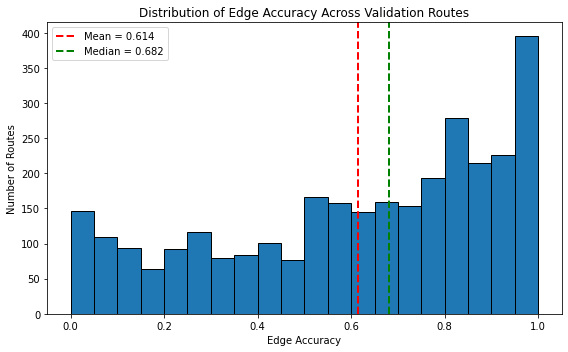

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    scores,
    bins=20,
    edgecolor="black"
)

plt.axvline(
    np.mean(scores),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {np.mean(scores):.3f}"
)

plt.axvline(
    np.median(scores),
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median = {np.median(scores):.3f}"
)

plt.xlabel("Edge Accuracy")
plt.ylabel("Number of Routes")
plt.title(
    "Distribution of Edge Accuracy Across Validation Routes"
)

plt.legend()

plt.tight_layout()

plt.show()

# Explainability

In [52]:
import shap

In [53]:
prep = model.named_steps["prep"]
rf = model.named_steps["rf"]

In [54]:
prep

/Users/ginevra/PycharmProjects/pythonProject/venv/lib/python3.9/site-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['depot_type'])])

In [55]:
X_transformed = prep.transform(
    validation_df[features]
)

feature_names = prep.get_feature_names_out()

In [56]:
#campionamento per non esplodere la ram
sample_idx = np.random.choice(
    X_transformed.shape[0],
    5000,
    replace=False
)

X_sample = X_transformed[sample_idx]

In [57]:
explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(
    X_sample
)

In [59]:
feature_names_clean = [
    f.replace("remainder__", "")
     .replace("cat__", "")
    for f in feature_names
]

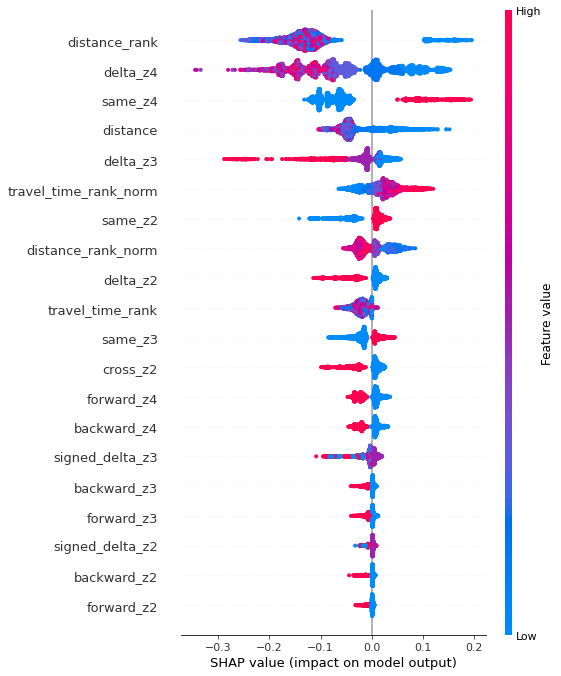

In [60]:
shap.summary_plot(
    shap_values[:,:,1],
    X_sample,
    feature_names=feature_names_clean
)

In [63]:
probs = rf.predict_proba(X_sample)[:,1]

In [64]:
feat_idx = feature_names_clean.index("distance_rank")

feat_values = X_sample[:, feat_idx]

In [65]:
tmp = pd.DataFrame({
    "distance_rank": feat_values,
    "prob": probs
})

tmp["bin"] = pd.qcut(
    tmp["distance_rank"],
    q=20,
    duplicates="drop"
)

In [66]:
curve = (
    tmp.groupby("bin")
       .agg(
           mean_rank=("distance_rank","mean"),
           mean_prob=("prob","mean")
       )
       .reset_index()
)

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_7853/4029871535.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby("bin")


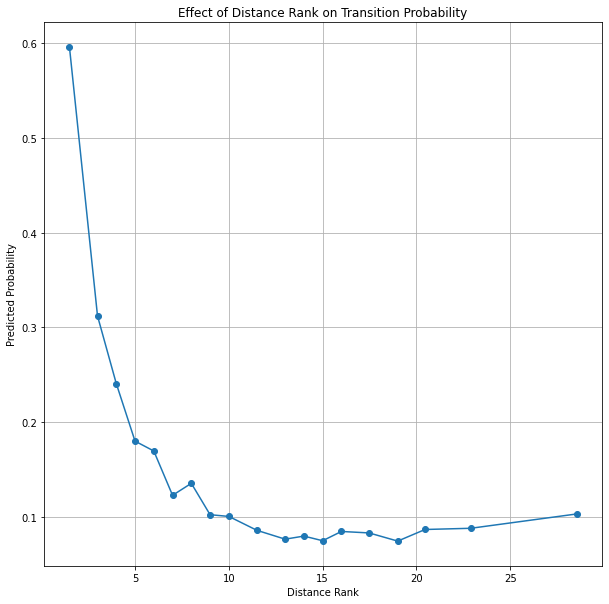

In [68]:
plt.figure(figsize=(10,10))

plt.plot(
    curve["mean_rank"],
    curve["mean_prob"],
    marker="o"
)

plt.xlabel("Distance Rank")
plt.ylabel("Predicted Probability")
plt.title(
    "Effect of Distance Rank on Transition Probability"
)

plt.grid(True)
plt.show()

In [69]:
#partial dependence:P(y=1)
#al variare di distance_rank mantenendo mediamente costanti le altre feature.
from sklearn.inspection import PartialDependenceDisplay

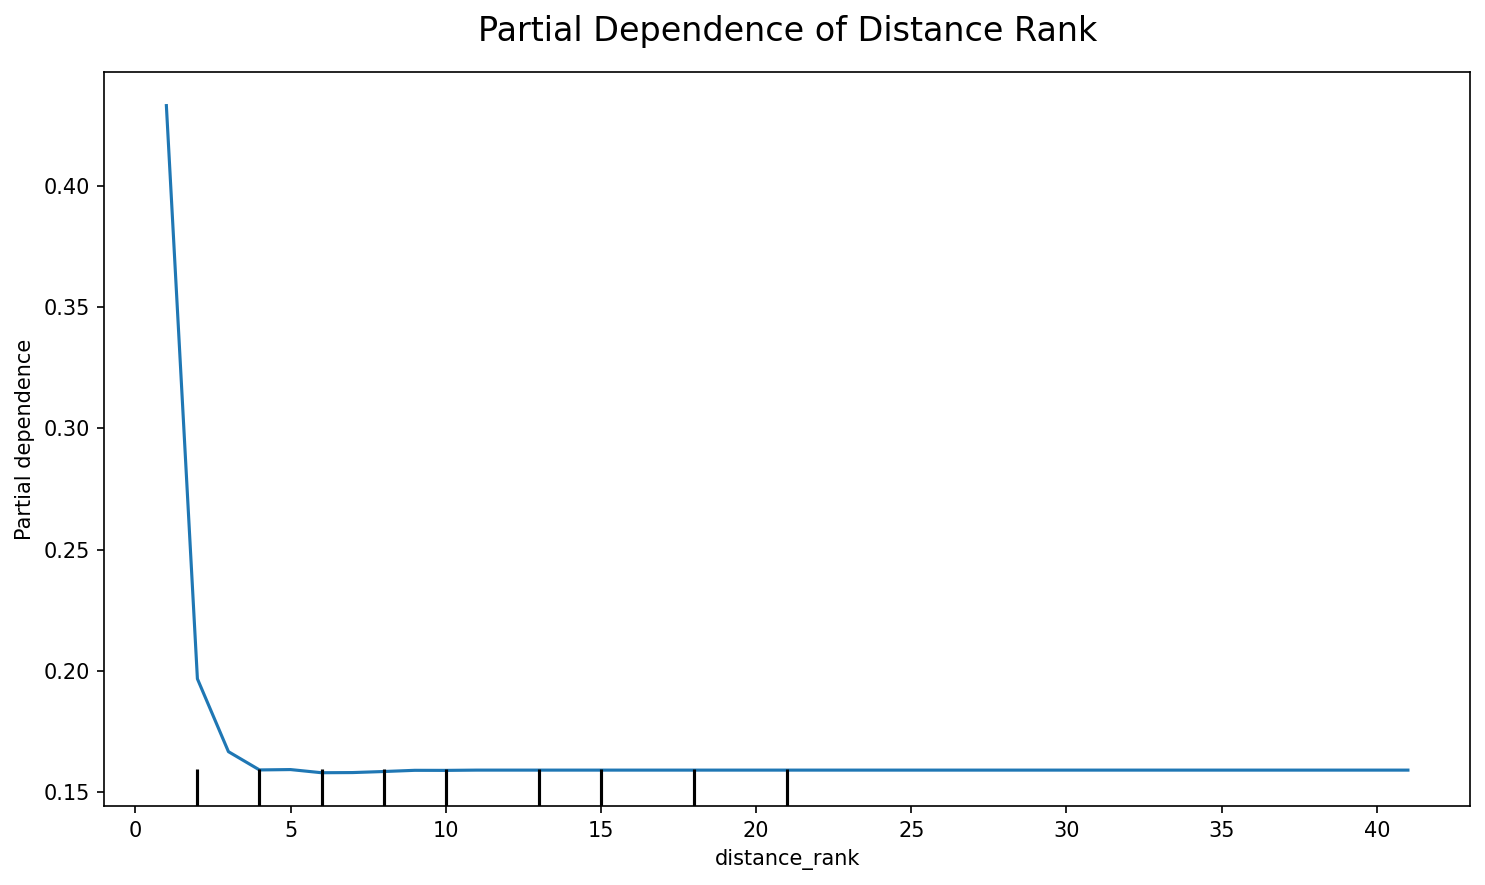

In [73]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=150
)

PartialDependenceDisplay.from_estimator(
    rf,
    X_sample,
    features=[
        feature_names_clean.index("distance_rank")
    ],
    feature_names=feature_names_clean,
    ax=ax,
    kind="average"
)

ax.set_title(
    "Partial Dependence of Distance Rank",
    fontsize=16,
    pad=15
)

ax.set_xlabel(
    "Distance Rank",
    fontsize=13
)

ax.set_ylabel(
    "Predicted Probability of Valid Transition",
    fontsize=13
)

ax.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()
plt.show()

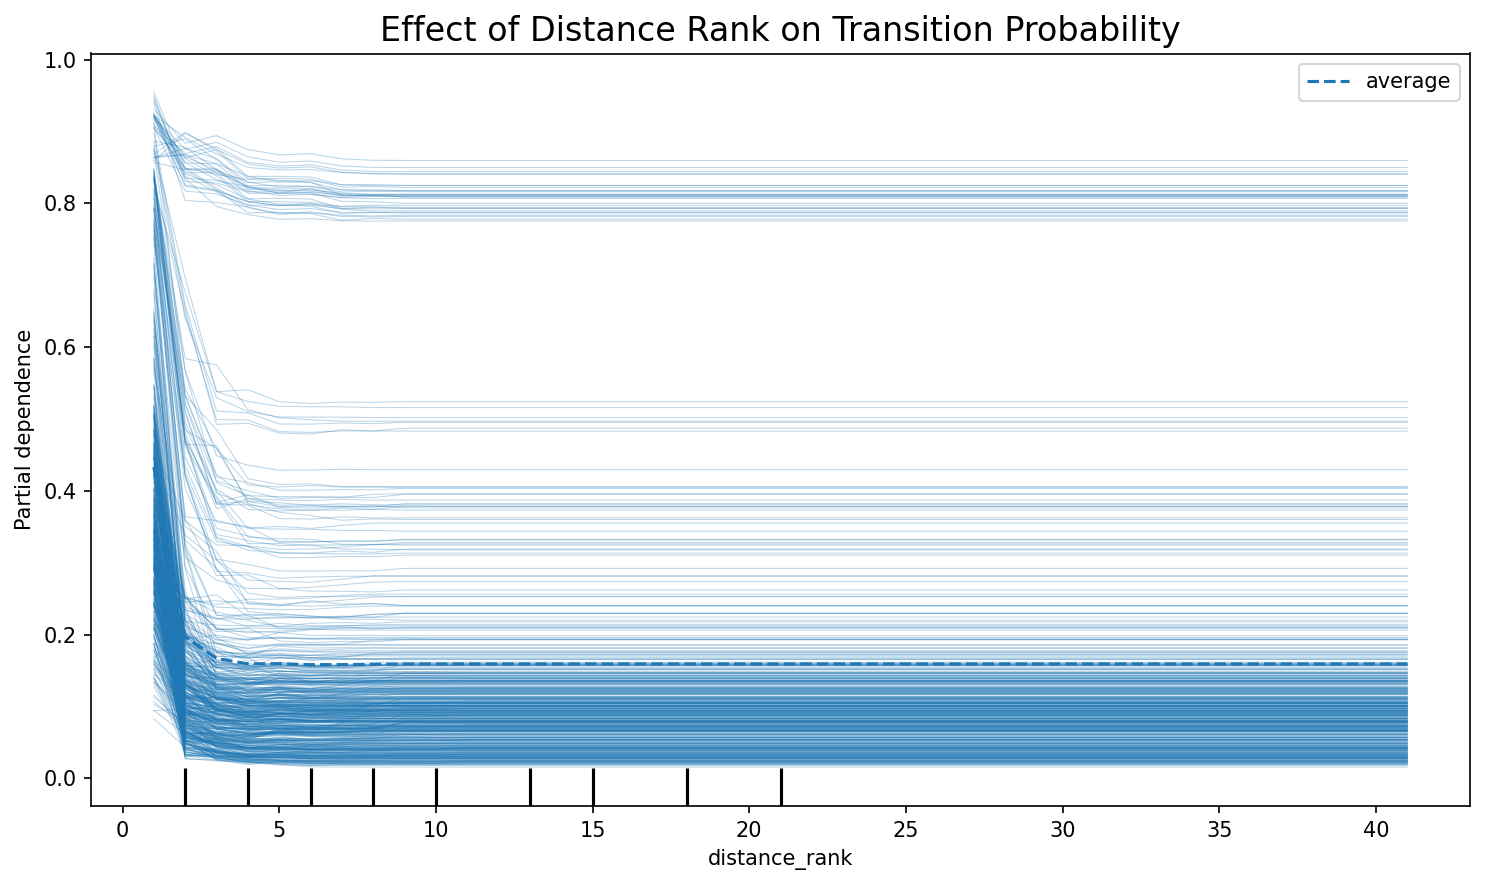

In [74]:
from sklearn.inspection import PartialDependenceDisplay

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=150
)

PartialDependenceDisplay.from_estimator(
    rf,
    X_sample,
    features=[
        feature_names_clean.index("distance_rank")
    ],
    feature_names=feature_names_clean,
    kind="both",      # PDP + ICE
    centered=False,
    subsample=500,
    random_state=42,
    ax=ax
)

ax.set_title(
    "Effect of Distance Rank on Transition Probability",
    fontsize=16
)

plt.tight_layout()
plt.show()

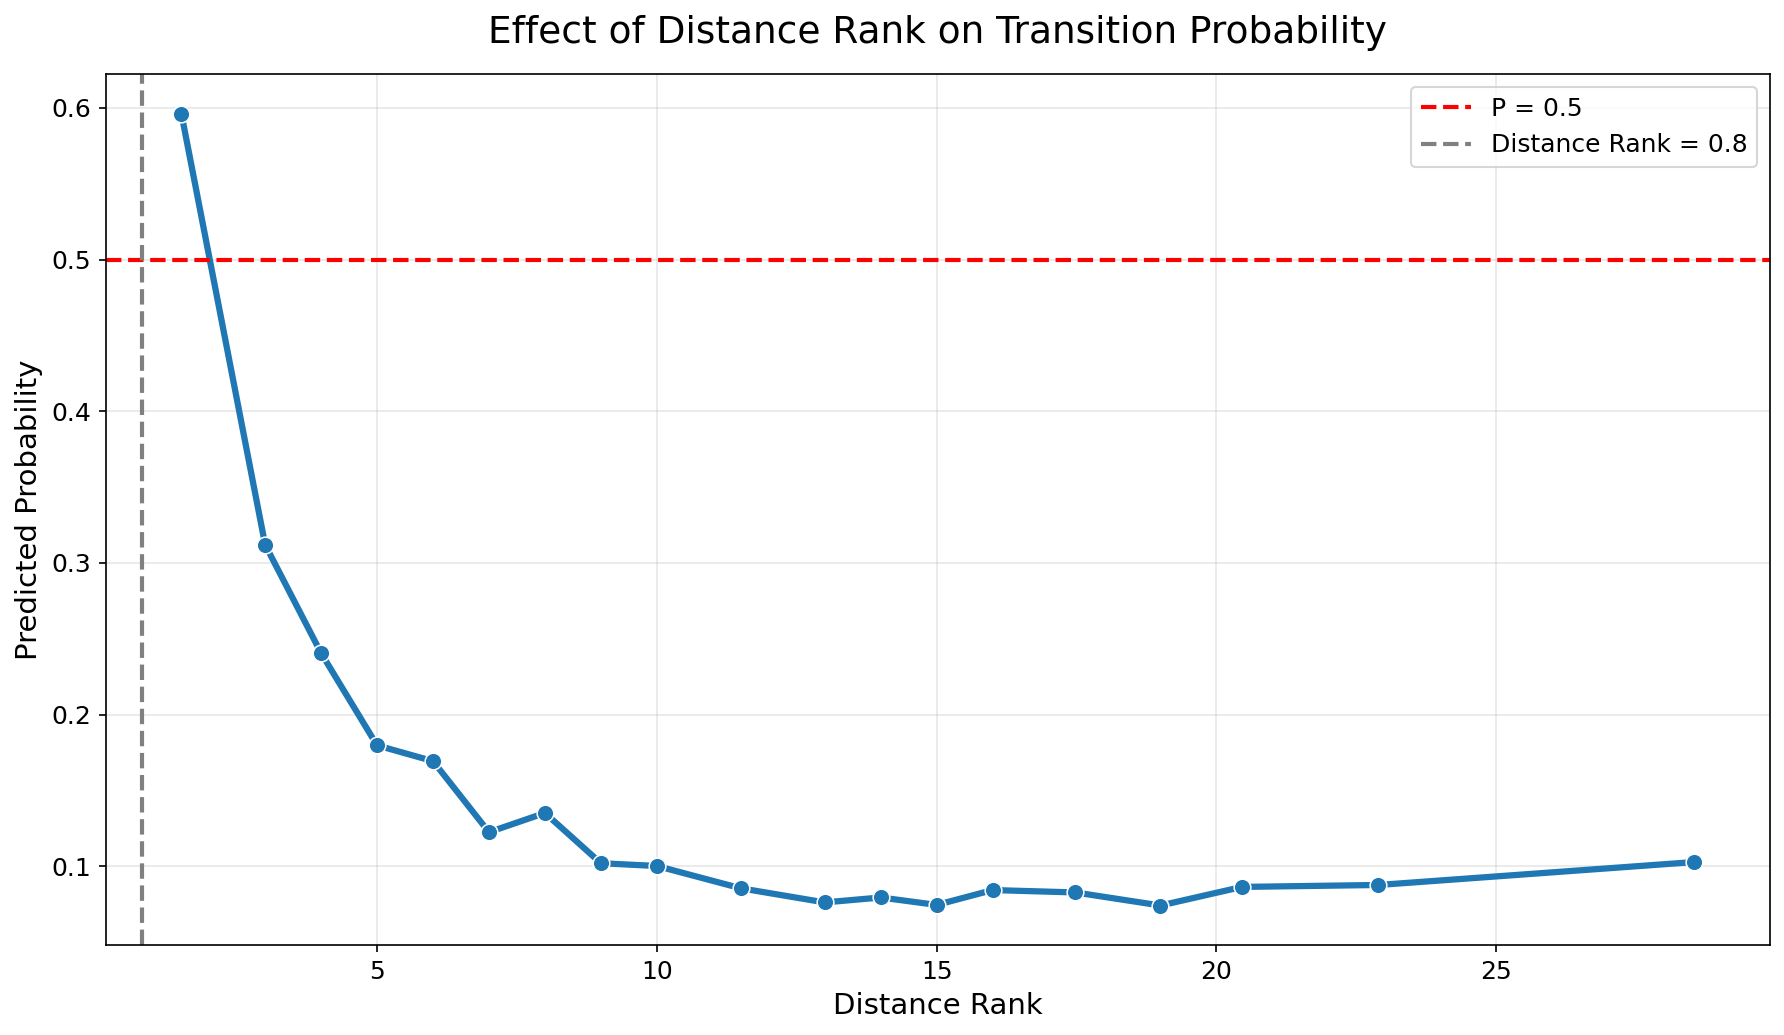

In [78]:
plt.figure(figsize=(12, 7), dpi=150)

sns.lineplot(
    data=curve,
    x="mean_rank",
    y="mean_prob",
    marker="o",
    linewidth=3,
    markersize=8
)

plt.axhline(
    0.5,
    color="red",
    ls="--",
    linewidth=2,
    label="P = 0.5"
)

plt.axvline(
    0.8,
    color="grey",
    ls="--",
    linewidth=2,
    label="Distance Rank = 0.8"
)

plt.xlabel("Distance Rank", fontsize=14)
plt.ylabel("Predicted Probability", fontsize=14)
plt.title(
    "Effect of Distance Rank on Transition Probability",
    fontsize=18,
    pad=15
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(alpha=0.3)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

In [82]:
#altre feat importanti
shap_class1 = shap_values[:, :, 1]
shap_importance = np.abs(shap_class1).mean(axis=0)

top5_idx = np.argsort(shap_importance)[-5:][::-1]

top5_features = [
    feature_names_clean[i]
    for i in top5_idx
]

top5_features

['distance_rank', 'delta_z4', 'same_z4', 'distance', 'delta_z3']

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_7853/829688440.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby("bin")


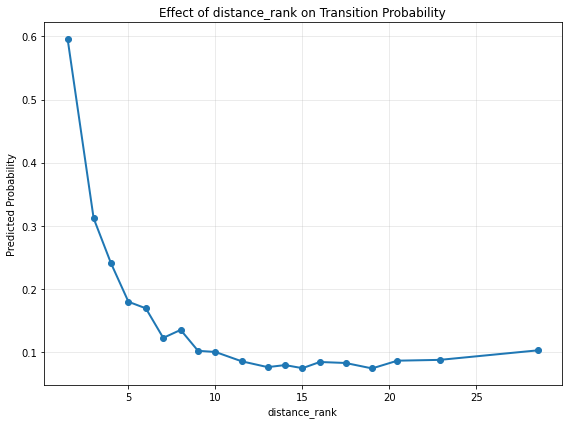

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_7853/829688440.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby("bin")


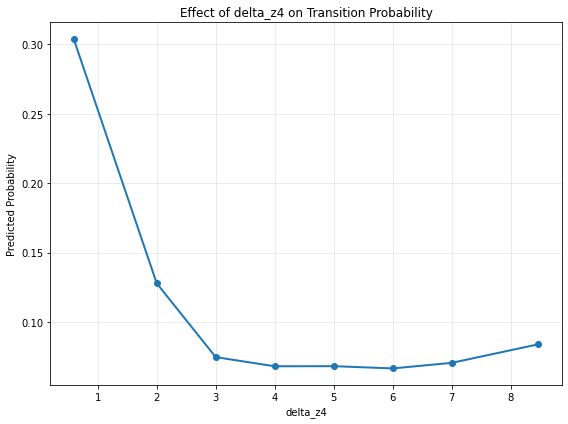

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_7853/829688440.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby("bin")


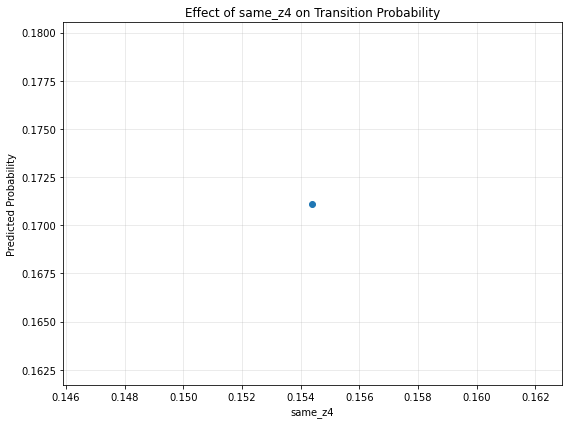

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_7853/829688440.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby("bin")


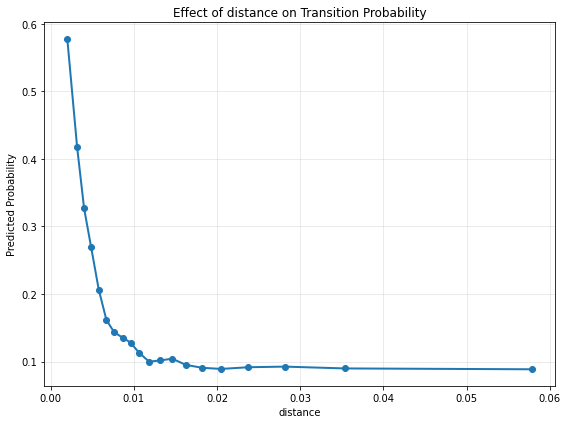

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_7853/829688440.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby("bin")


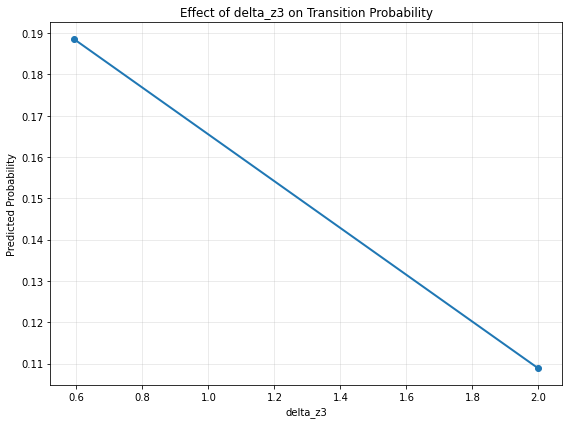

In [83]:
probs = rf.predict_proba(X_sample)[:, 1]

for feat_name in top5_features:

    feat_idx = feature_names_clean.index(feat_name)

    feat_values = X_sample[:, feat_idx]

    tmp = pd.DataFrame({
        "feature": feat_values,
        "prob": probs
    })

    tmp["bin"] = pd.qcut(
        tmp["feature"],
        q=20,
        duplicates="drop"
    )

    curve = (
        tmp.groupby("bin")
        .agg(
            mean_feature=("feature", "mean"),
            mean_prob=("prob", "mean")
        )
        .reset_index()
    )

    plt.figure(figsize=(8, 6))

    plt.plot(
        curve["mean_feature"],
        curve["mean_prob"],
        marker="o",
        linewidth=2
    )

    plt.xlabel(feat_name)
    plt.ylabel("Predicted Probability")
    plt.title(
        f"Effect of {feat_name} on Transition Probability"
    )

    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_7853/2302135495.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby("bin")
/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_7853/2302135495.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby("bin")
/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_7853/2302135495.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tm

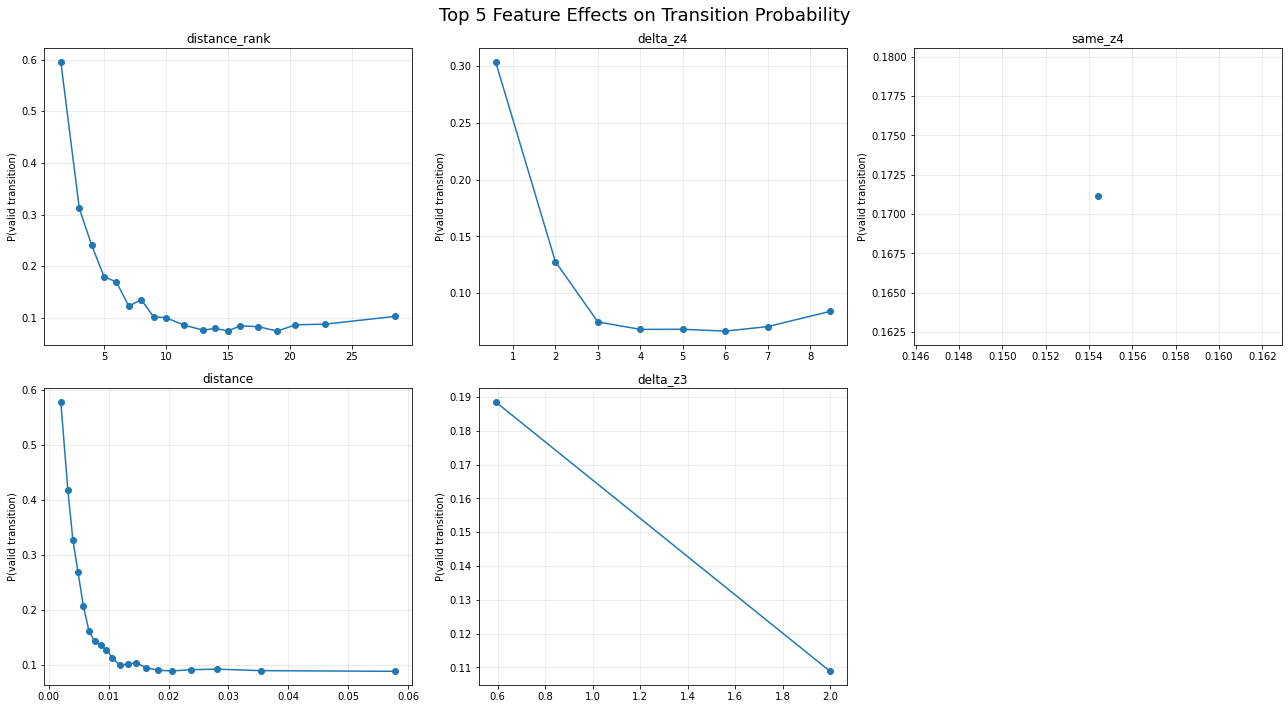

In [84]:
probs = rf.predict_proba(X_sample)[:, 1]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 10)
)

axes = axes.ravel()

for i, feat_name in enumerate(top5_features):

    feat_idx = feature_names_clean.index(feat_name)

    feat_values = X_sample[:, feat_idx]

    tmp = pd.DataFrame({
        "feature": feat_values,
        "prob": probs
    })

    tmp["bin"] = pd.qcut(
        tmp["feature"],
        q=20,
        duplicates="drop"
    )

    curve = (
        tmp.groupby("bin")
        .agg(
            mean_feature=("feature", "mean"),
            mean_prob=("prob", "mean")
        )
        .reset_index()
    )

    axes[i].plot(
        curve["mean_feature"],
        curve["mean_prob"],
        marker="o"
    )

    axes[i].set_title(feat_name)
    axes[i].set_ylabel("P(valid transition)")
    axes[i].grid(alpha=0.3)

# nasconde il 6° pannello vuoto
axes[-1].axis("off")

plt.suptitle(
    "Top 5 Feature Effects on Transition Probability",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [87]:
validation_df["delta_z3"].value_counts().head(20)

delta_z3
 1    554684
 0    367598
 2    267112
-1       178
Name: count, dtype: int64

In [88]:
validation_df["same_z4"].value_counts().head(20)

same_z4
0    1003396
1     186176
Name: count, dtype: int64

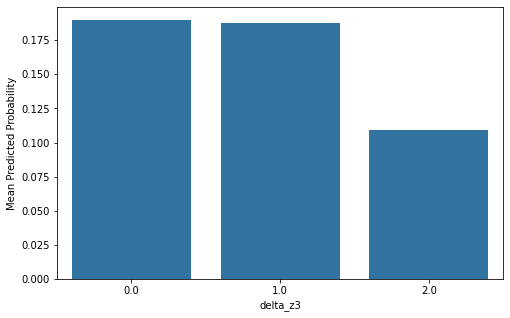

In [89]:
tmp = pd.DataFrame({
    "feature": feat_values,
    "prob": probs
})

agg = (
    tmp.groupby("feature")
       .prob
       .mean()
       .reset_index()
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=agg,
    x="feature",
    y="prob"
)

plt.ylabel("Mean Predicted Probability")
plt.xlabel(feat_name)

plt.show()

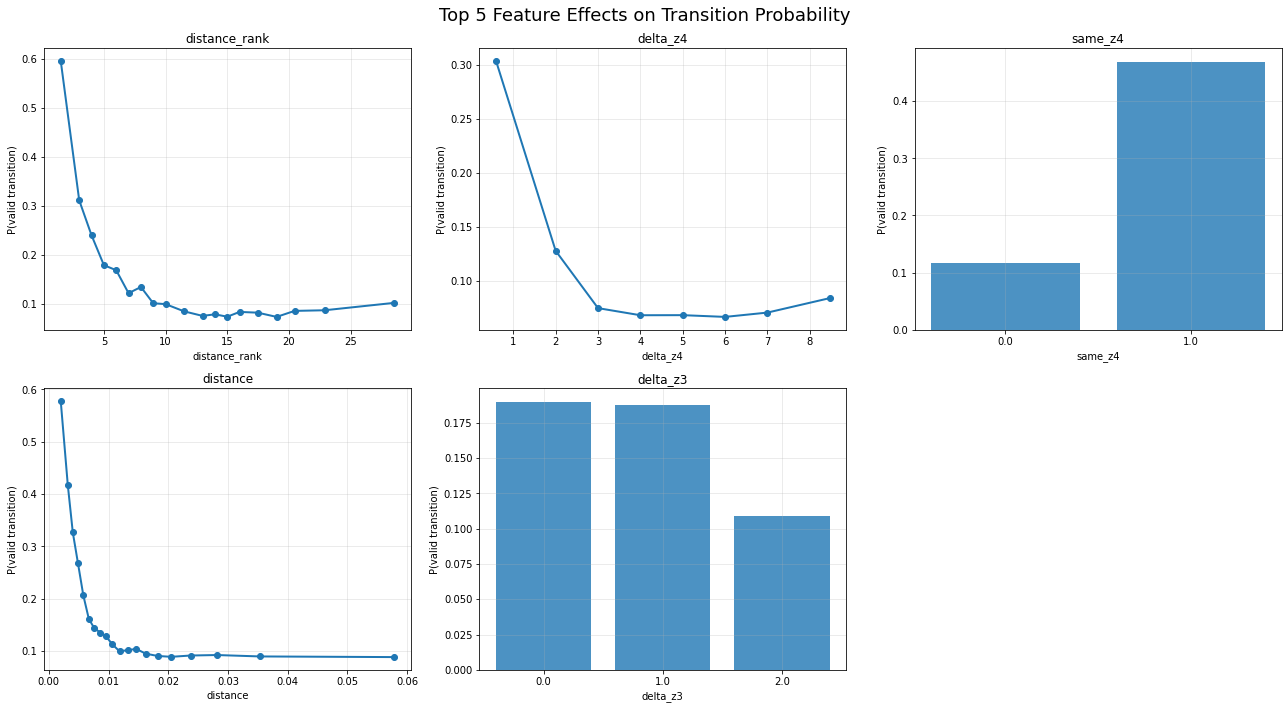

In [90]:
probs = rf.predict_proba(X_sample)[:, 1]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 10)
)

axes = axes.ravel()

for i, feat_name in enumerate(top5_features):

    feat_idx = feature_names_clean.index(feat_name)

    feat_values = X_sample[:, feat_idx]

    tmp = pd.DataFrame({
        "feature": feat_values,
        "prob": probs
    })

    # FEATURE DISCRETE
    if feat_name in ["same_z4", "delta_z3"]:

        agg = (
            tmp.groupby("feature")
               .agg(mean_prob=("prob", "mean"))
               .reset_index()
               .sort_values("feature")
        )

        axes[i].bar(
            agg["feature"].astype(str),
            agg["mean_prob"],
            alpha=0.8
        )

        axes[i].set_xlabel(feat_name)

    # FEATURE CONTINUE
    else:

        tmp["bin"] = pd.qcut(
            tmp["feature"],
            q=20,
            duplicates="drop"
        )

        curve = (
            tmp.groupby("bin", observed=False)
            .agg(
                mean_feature=("feature", "mean"),
                mean_prob=("prob", "mean")
            )
            .reset_index()
        )

        axes[i].plot(
            curve["mean_feature"],
            curve["mean_prob"],
            marker="o",
            linewidth=2
        )

        axes[i].set_xlabel(feat_name)

    axes[i].set_ylabel("P(valid transition)")
    axes[i].set_title(feat_name)
    axes[i].grid(alpha=0.3)

# pannello vuoto
axes[-1].axis("off")

plt.suptitle(
    "Top 5 Feature Effects on Transition Probability",
    fontsize=18
)

plt.tight_layout()
plt.show()